# Feature engineering de las consultas

Cada consulta se representa por características de tres tipos: la forma del texto, el tema léxico y la búsqueda sobre el corpus.

1. Leyenda de las etiquetas del conjunto.
2. Distribución del conjunto.
3. Características de forma.
4. Características de tema.
5. Características de la búsqueda.
6. Síntesis.


In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

import pandas as pd
import matplotlib.pyplot as plt

from thesis_routing.features import build_feature_table

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.max_rows", 40)

QB = ROOT / "data" / "processed" / "question_bank" / "consultas_piloto.csv"
INV = ROOT / "data" / "processed" / "corpus" / "inventario_documental.csv"
TEXT_DIR = ROOT / "data" / "interim" / "extracted_text"
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed" / "features"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIA = {
    "N": "Norma o calendario",
    "R": "Malla o prerrequisito",
    "M": "Varias fuentes",
    "A": "Trámite o persona",
}
ORIGEN = {
    "faq": "Preguntas frecuentes",
    "documento": "Reglamento",
    "malla_demo": "Malla de ejemplo",
}
TEMA = {
    "otro": "Sin tema claro",
    "matricula": "Matrícula",
    "pagos": "Pagos",
    "tramites": "Trámites",
    "horarios": "Horarios",
    "prerrequisitos": "Prerrequisitos",
    "calendario": "Calendario",
}
DOC = {
    "D001": "Reglamento académico",
    "D002": "Reglamento de matrícula",
    "D003": "Reglamento general",
    "D004": "Reglamento económico",
    "D005": "Grados y títulos",
    "D006": "Admisión",
    "D007": "Becas",
    "D008": "Tutoría",
    "D009": "Convalidaciones",
    "D011": "Tarifario",
    "D012": "Preguntas frecuentes",
}

qb = pd.read_csv(QB)
inv = pd.read_csv(INV)
fe = build_feature_table(qb, text_dir=TEXT_DIR, inventory=inv)
print(f"Consultas listas para el análisis: {len(fe)}")


Consultas listas para el análisis: 196


## 1. Leyenda de las etiquetas

### 1.1 Categoría

| Código | Significado |
|--------|-------------|
| N | Norma, reglamento o calendario |
| R | Malla, prerrequisito o avance curricular |
| M | Más de una fuente |
| A | Trámite que corresponde a una persona o al sistema de la universidad |

### 1.2 Complejidad

| Nivel | Significado |
|-------|-------------|
| Baja | Un dato localizable en un solo lugar |
| Media | Una fuente, con condiciones o de localización menos directa |
| Alta | Varias fuentes, reglas encadenadas o una herramienta |

### 1.3 Origen

| Origen | Significado |
|--------|-------------|
| Preguntas frecuentes | Texto de la página de preguntas de la UMA |
| Reglamento | Texto elaborado a partir de un documento del corpus |
| Malla de ejemplo | Caso de prerrequisitos construido para el piloto |


## 2. Origen de las consultas


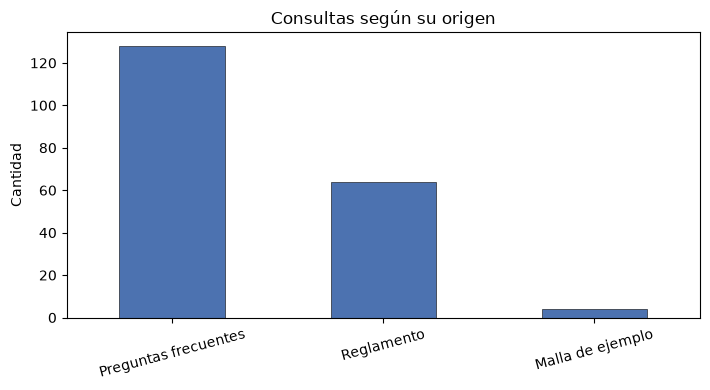

In [2]:
conteo_origen = (
    fe["origen"].map(ORIGEN).value_counts()
    .reindex(["Preguntas frecuentes", "Reglamento", "Malla de ejemplo"])
)
fig, ax = plt.subplots(figsize=(7.2, 4))
conteo_origen.plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black", linewidth=0.4)
ax.set_title("Consultas según su origen")
ax.set_xlabel("")
ax.set_ylabel("Cantidad")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_origen.png", dpi=140)
plt.show()


## 3. Categoría


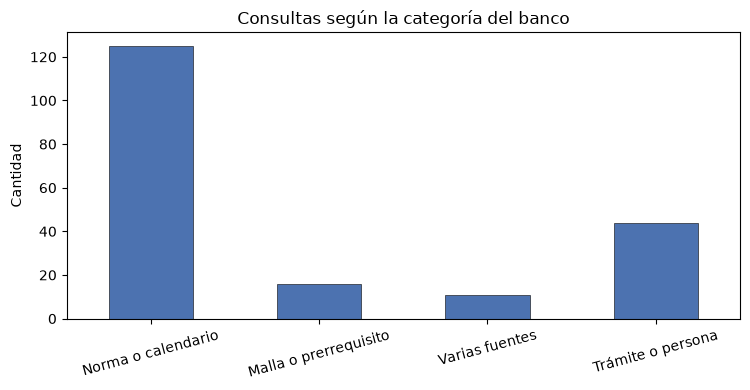

In [3]:
orden_cat = ["N", "R", "M", "A"]
conteo_cat = fe["categoria"].value_counts().reindex(orden_cat)
conteo_cat.index = [CATEGORIA[c] for c in conteo_cat.index]
fig, ax = plt.subplots(figsize=(7.6, 4))
conteo_cat.plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black", linewidth=0.4)
ax.set_title("Consultas según la categoría del banco")
ax.set_xlabel("")
ax.set_ylabel("Cantidad")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_categoria.png", dpi=140)
plt.show()


## 4. Complejidad


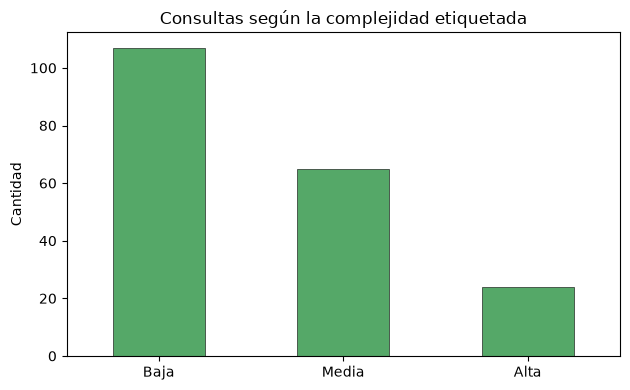

In [4]:
orden_comp = ["baja", "media", "alta"]
conteo_comp = fe["complejidad"].value_counts().reindex(orden_comp)
conteo_comp.index = ["Baja", "Media", "Alta"]
fig, ax = plt.subplots(figsize=(6.4, 4))
conteo_comp.plot(kind="bar", ax=ax, color="#55A868", edgecolor="black", linewidth=0.4)
ax.set_title("Consultas según la complejidad etiquetada")
ax.set_xlabel("")
ax.set_ylabel("Cantidad")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_complejidad.png", dpi=140)
plt.show()


## 5. Muestra de consultas


In [5]:
muestra = pd.DataFrame({
    "Número": fe["query_id"].head(5),
    "Pregunta": fe["pregunta"].head(5),
    "Categoría": fe["categoria"].head(5).map(CATEGORIA),
    "Complejidad": fe["complejidad"].head(5).str.capitalize(),
    "Origen": fe["origen"].head(5).map(ORIGEN),
})
display(muestra.reset_index(drop=True))


,Número,Pregunta,Categoría,Complejidad,Origen
0,Q001,¿Qué modalidades de estudio tiene la UMA?,Norma o calendario,Baja,Preguntas frecuentes
1,Q002,¿Pueden deshabilitarme por inasistencias?,Norma o calendario,Media,Preguntas frecuentes
2,Q003,¿Qué es el examen sustitutorio y quiénes pueden acceder?,Norma o calendario,Media,Preguntas frecuentes
3,Q004,¿En qué consiste el curso o examen de aplazados?,Norma o calendario,Alta,Preguntas frecuentes
4,Q005,¿Dónde reviso mis horarios de clase actualizados?,Trámite o persona,Baja,Preguntas frecuentes


## 6. Características de forma

La primera técnica registra la longitud de la pregunta y la presencia de negación, condición, comparación y referencia al caso del estudiante.

### 6.1 Leyenda

| Característica | Definición |
|----------------|------------|
| Caracteres | Número de caracteres de la pregunta |
| Palabras | Número de palabras |
| Signos de interrogación | Número de signos de cierre de interrogación |
| Más de una pregunta | Presencia de más de un signo de cierre |
| Negación | Presencia de no, nunca, tampoco, sin o ni |
| Condición | Presencia de si, siempre que, en caso de, mientras o aunque |
| Comparación | Pedido de una diferencia entre dos elementos |
| Caso propio | Presencia de mi, mis, puedo, estoy o desaprobé |

La partícula si se toma como palabra independiente.


### 6.2 Frecuencia


In [6]:
marcas_texto = pd.DataFrame({
    "Marca": [
        "Caso contado por el alumno",
        "Tiene una condición",
        "Tiene una negación",
        "Más de una pregunta",
        "Pide una comparación",
    ],
    "Consultas": [
        int(fe["contains_personal_case"].sum()),
        int(fe["contains_condition"].sum()),
        int(fe["contains_negation"].sum()),
        int(fe["has_multiple_questions"].sum()),
        int(fe["contains_comparison"].sum()),
    ],
})
marcas_texto["Porcentaje"] = (100 * marcas_texto["Consultas"] / len(fe)).round(1)
display(marcas_texto)


,Marca,Consultas,Porcentaje
0,Caso contado por el alumno,75,38.3
1,Tiene una condición,24,12.2
2,Tiene una negación,8,4.1
3,Más de una pregunta,0,0.0
4,Pide una comparación,0,0.0


### 6.3 Interpretación

La comparación y la pregunta múltiple no aparecen en el conjunto. El caso propio aparece en 75 consultas, en fórmulas como mi carrera o mis horarios.


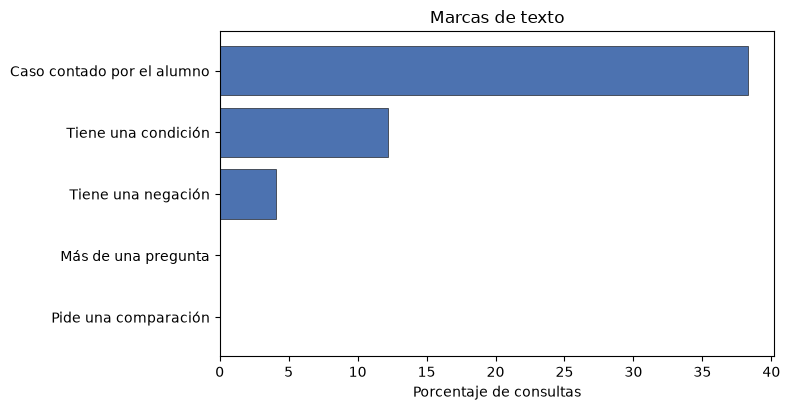

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(
    marcas_texto["Marca"][::-1],
    marcas_texto["Porcentaje"][::-1],
    color="#4C72B0",
    edgecolor="black",
    linewidth=0.4,
)
ax.set_xlabel("Porcentaje de consultas")
ax.set_title("Marcas de texto")
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_marcas_texto.png", dpi=140)
plt.show()


### 6.4 Palabras y complejidad


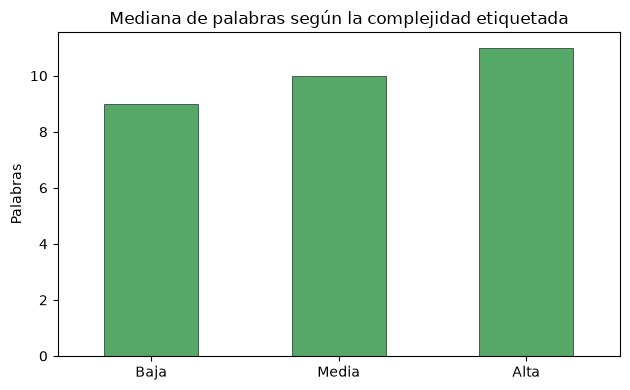

In [8]:
mediana = (
    fe.groupby("complejidad")["query_length_words"]
    .median()
    .reindex(["baja", "media", "alta"])
)
mediana.index = ["Baja", "Media", "Alta"]
fig, ax = plt.subplots(figsize=(6.4, 4))
mediana.plot(kind="bar", ax=ax, color="#55A868", edgecolor="black", linewidth=0.4)
ax.set_title("Mediana de palabras según la complejidad etiquetada")
ax.set_xlabel("")
ax.set_ylabel("Palabras")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_longitud_por_complejidad.png", dpi=140)
plt.show()


### 6.5 Interpretación

La mediana es de 9 palabras en complejidad baja, 10 en media y 11 en alta. La correlación entre caracteres y palabras es 0,90. La condición aparece en 2 de las 24 consultas de complejidad alta.


## 7. Características de tema

La segunda técnica asigna un tema con una lista de términos. Si la pregunta contiene más de un tema, se conserva el más específico: prerrequisito precede a matrícula, y matrícula precede a pago.

### 7.1 Leyenda

| Característica | Definición |
|----------------|------------|
| Tema detectado | Matrícula, pagos, trámites, horarios, prerrequisitos, calendario, o sin tema reconocido |
| Cantidad de temas | Número de temas de la lista presentes en la pregunta |
| Varias fuentes | Dos temas, o un nexo como además |
| Caso del estudiante | Presencia de puedo, cumplo, desaprobé o perdí |
| Cálculo | Presencia de cuánto, suma, porcentaje o costo |
| Verificación de una regla | Presencia de puedo, requisito, debo o desaprob |
| Fecha | Presencia de cuándo, todavía, plazo o fecha |
| Término académico | Presencia de ciclo, curso, crédito, malla, examen o nota |
| Término de trámite | Presencia de matrícula, pago, carné, diploma o SIGU |


### 7.2 Distribución del tema


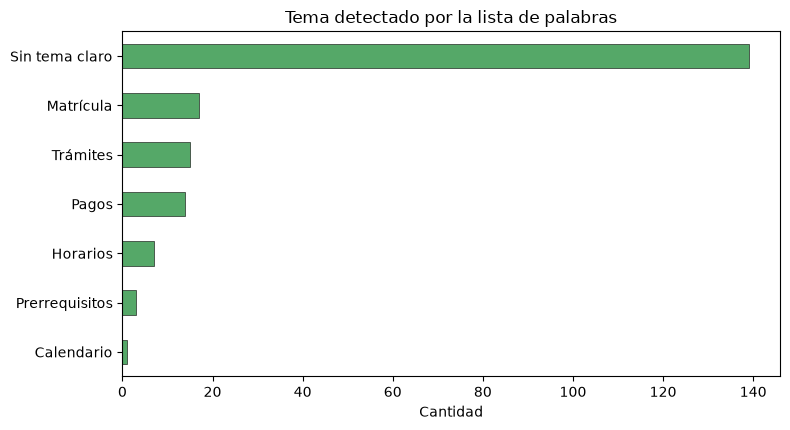

In [9]:
orden_tema = [
    "otro", "matricula", "tramites", "pagos",
    "horarios", "prerrequisitos", "calendario",
]
conteo_tema = fe["intent_category"].value_counts().reindex(orden_tema).fillna(0).astype(int)
conteo_tema.index = [TEMA[t] for t in conteo_tema.index]
fig, ax = plt.subplots(figsize=(8, 4.4))
conteo_tema.sort_values().plot(
    kind="barh", ax=ax, color="#55A868", edgecolor="black", linewidth=0.4
)
ax.set_xlabel("Cantidad")
ax.set_title("Tema detectado por la lista de palabras")
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_intencion.png", dpi=140)
plt.show()


### 7.3 Interpretación

139 de 196 consultas quedan sin tema reconocido.


### 7.4 Otras marcas de tema


In [10]:
marcas_tema = pd.DataFrame({
    "Marca": [
        "Pide verificar una regla",
        "Menciona un trámite",
        "Depende del caso del estudiante",
        "Menciona lo académico",
        "Parece pedir varias fuentes",
        "Pide un cálculo",
        "Depende de una fecha",
    ],
    "Consultas": [
        int(fe["requires_rule_validation"].sum()),
        int(fe["contains_administrative_entity"].sum()),
        int(fe["requires_personal_context"].sum()),
        int(fe["contains_academic_entity"].sum()),
        int(fe["requires_multiple_sources_rule"].sum()),
        int(fe["requires_calculation"].sum()),
        int(fe["requires_temporal_reasoning"].sum()),
    ],
})
marcas_tema["Porcentaje"] = (100 * marcas_tema["Consultas"] / len(fe)).round(1)
display(marcas_tema)


,Marca,Consultas,Porcentaje
0,Pide verificar una regla,43,21.9
1,Menciona un trámite,41,20.9
2,Depende del caso del estudiante,36,18.4
3,Menciona lo académico,24,12.2
4,Parece pedir varias fuentes,11,5.6
5,Pide un cálculo,7,3.6
6,Depende de una fecha,7,3.6


### 7.5 Interpretación

La verificación de una regla es la marca más frecuente. El cálculo y la fecha son poco frecuentes.


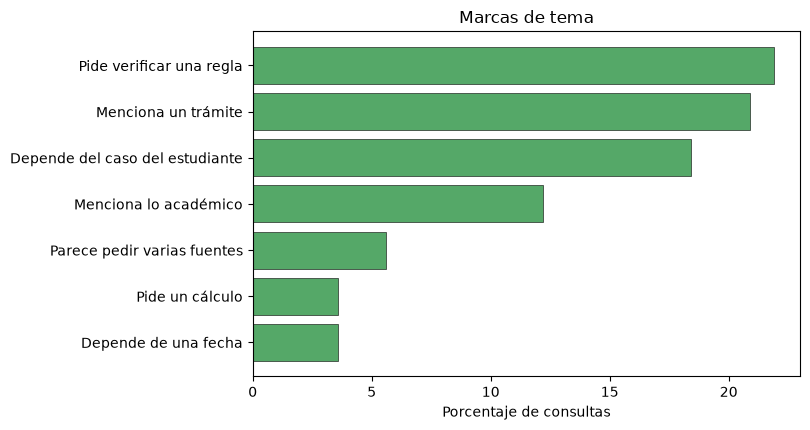

In [11]:
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.barh(
    marcas_tema["Marca"][::-1],
    marcas_tema["Porcentaje"][::-1],
    color="#55A868",
    edgecolor="black",
    linewidth=0.4,
)
ax.set_xlabel("Porcentaje de consultas")
ax.set_title("Marcas de tema")
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_marcas_tema.png", dpi=140)
plt.show()


### 7.6 Cruce con la categoría

La figura cruza la categoría del conjunto con el tema asignado. Cada celda es un conteo.


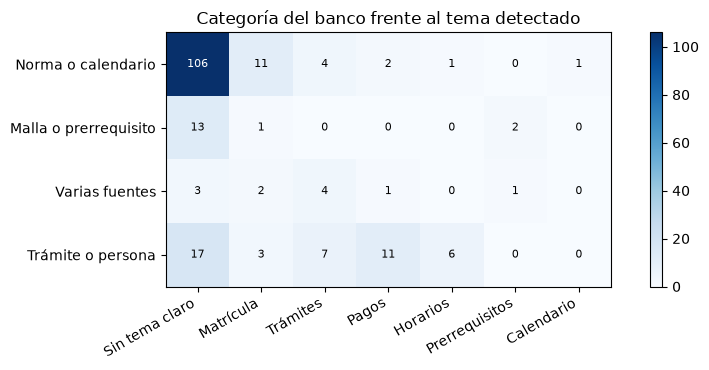

In [12]:
tabla = pd.crosstab(fe["categoria"], fe["intent_category"])
tabla = tabla.reindex(index=["N", "R", "M", "A"], columns=orden_tema).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(10.2, 3.8))
im = ax.imshow(tabla.values, cmap="Blues")
ax.set_xticks(range(tabla.shape[1]))
ax.set_xticklabels([TEMA[c] for c in tabla.columns], rotation=30, ha="right")
ax.set_yticks(range(tabla.shape[0]))
ax.set_yticklabels([CATEGORIA[i] for i in tabla.index])
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        valor = int(tabla.values[i, j])
        color = "white" if valor > tabla.values.max() * 0.55 else "black"
        ax.text(j, i, valor, ha="center", va="center", color=color, fontsize=8)
ax.set_title("Categoría del banco frente al tema detectado")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_categoria_vs_tema.png", dpi=140)
plt.show()


### 7.7 Interpretación

De las 16 consultas de malla o prerrequisito, el tema prerrequisito se asigna a 3.


## 8. Características de la búsqueda

La tercera técnica calcula un puntaje BM25 entre la pregunta y cada documento del corpus. El índice reúne 11 documentos con texto utilizable. D010 queda fuera del índice.

El puntaje corresponde a una búsqueda ya realizada sobre esos documentos.

### 8.1 Leyenda

| Característica | Definición |
|----------------|------------|
| Puntaje del mejor documento | BM25 del documento en primer lugar |
| Puntaje medio de los tres mejores | Media de los tres puntajes más altos |
| Diferencia entre el primero y el segundo | Margen entre los dos primeros puntajes |
| Documentos con puntaje positivo | Documentos cuyo puntaje es mayor que cero |
| Fuentes con puntaje positivo | Fuentes distintas con puntaje mayor que cero |
| Documento en primer lugar | Identificador del documento de mayor puntaje |


### 8.2 Documento en primer lugar


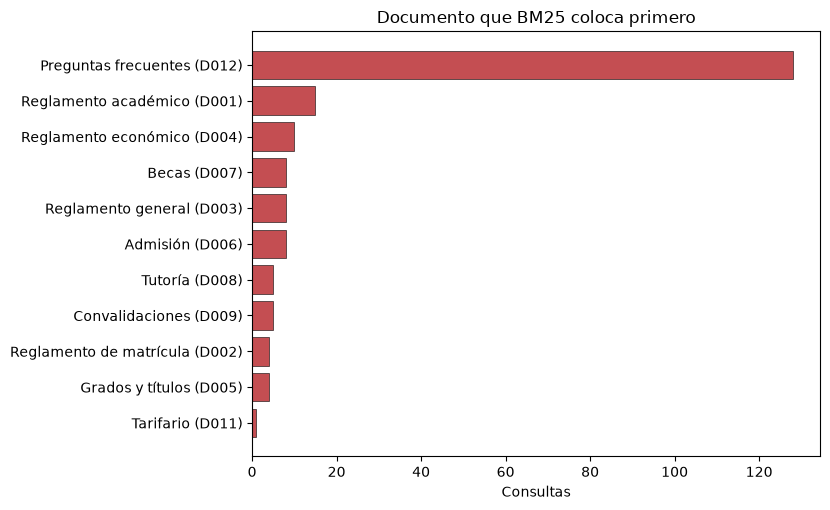

In [13]:
top = fe["top1_doc_id"].value_counts()
etiquetas = [f"{DOC.get(i, i)} ({i})" for i in top.index]
fig, ax = plt.subplots(figsize=(8.4, 5.2))
ax.barh(etiquetas[::-1], top.values[::-1], color="#C44E52", edgecolor="black", linewidth=0.4)
ax.set_xlabel("Consultas")
ax.set_title("Documento que BM25 coloca primero")
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_bm25_top1.png", dpi=140)
plt.show()


### 8.3 Interpretación

Preguntas frecuentes ocupa el primer lugar en 128 consultas, igual al número de consultas de ese origen.


### 8.4 Coincidencia con el documento de referencia


In [14]:
coincide = fe["top1_doc_id"].astype(str) == fe["doc_referencia"].astype(str)
cruce = (
    fe.assign(coincide=coincide)
    .groupby("origen")
    .agg(Consultas=("query_id", "size"), Coinciden=("coincide", "sum"))
    .reindex(["faq", "documento", "malla_demo"])
)
cruce.index = [ORIGEN[i] for i in cruce.index]
cruce["Porcentaje"] = (100 * cruce["Coinciden"] / cruce["Consultas"]).round(1)
cruce = cruce.reset_index().rename(columns={"origen": "Origen", "index": "Origen"})
if "index" in cruce.columns:
    cruce = cruce.rename(columns={"index": "Origen"})
display(cruce)


,Origen,Consultas,Coinciden,Porcentaje
0,Preguntas frecuentes,128,112,87.5
1,Reglamento,64,26,40.6
2,Malla de ejemplo,4,0,0.0


### 8.5 Interpretación

La coincidencia es de 70,4 % en el conjunto, 87,5 % en preguntas frecuentes y 40,6 % en reglamentos. En las cuatro consultas de malla de ejemplo no hay coincidencia.

La mediana de documentos con puntaje positivo es 10, sobre 11 documentos del índice.


## 9. Conjuntos de características

| Conjunto | Características | Objeto |
|----------|-----------------|--------|
| F0 | Forma del texto | Línea de base |
| F1 | F0 y tema | Aporte del léxico de tema |
| F2 | F1 y búsqueda | Aporte del puntaje BM25 |

F0 y F1 se obtienen de la pregunta. F2 incorpora el puntaje de la búsqueda.


## 10. Registro

Las características de las 196 consultas quedan en `data/processed/features/consultas_features.csv`.


In [15]:
csv_path = OUT_DIR / "consultas_features.csv"
fe.to_csv(csv_path, index=False)
print(f"Archivo: {csv_path.name}")
print(f"Filas: {len(fe)}")
print(f"Columnas: {fe.shape[1]}")


Archivo: consultas_features.csv
Filas: 196
Columnas: 33


## 11. Síntesis

El conjunto tiene 196 consultas: 128 de preguntas frecuentes, 64 de reglamentos y 4 de malla de ejemplo. La respuesta esperada está vacía en 185 consultas.

La longitud varía poco entre niveles de complejidad. El léxico de tema deja 139 consultas sin tema reconocido. El documento de mayor puntaje BM25 coincide, sobre todo, con las consultas de preguntas frecuentes.
